# How to simulate a scanning-3DXRD dataset

`python -m anri.simulate` simulates a scanning-3DXRD dataset from a map, as ImageD11 files that ImageD11 and `python -m anri.index` read. It runs in three stages, each writing one file that the next one reads:

| Stage | What it does | Options | What the plots show |
|---|---|---|---|
| `prepare` | map entries per phase, reflections and structure factors, absorption, the beam's spreads, the scan's motor positions | `--optics`, `--bandwidth`, `--beam-fwhm`, `--dty-step`, `--margin`, `--omega-step`, `--tth-max`, `--density`, `--cif`, `--mu`, `--mu-map`, `--no-absorption` | the sample against the rows' reach; each ring's share of the detector |
| `render` | rows of the scan rendered into sparse pixels above the segmentation cut; rows can be split between jobs (`--rows a:b`) | `--cut`, `--window`, `--max-frames`, `--batch` | how peaks survive the cut at each density; how much of each peak its window holds |
| `assemble` | the rendered rows gathered into an ImageD11 dataset (`_sparse.h5`, `pars/`, the DataSet), and optionally ImageD11's peaks table | `--peaks-table` | a rendered row, summed over its frames |

This notebook runs the same stages, with the plots that help choose each option (`anri.simulate.diagnostics` and `anri.simulate.plots`). The files it writes are the command line's, with the same provenance, and it ends with the `python -m anri.simulate run` command that remakes them.

By default it renders the [AM-like 316L phantom](../tutorials/phantom.ipynb) shipped in `tests/data/phantoms/am316l` (38 grains with misoriented cells and twin lamellae, 0.5 µm voxels), on an Eiger 4M at 43.6 keV with ID11's Al CRLs: 57 rows of 1 µm, 1800 frames of 0.1°. The render takes about two minutes on a GPU, so this notebook is stored with its outputs and not re-run when the docs are built. With `interactive = True` (the default when you run it), sliders redraw the plots, and **the value on a slider is what the later cells use**; it needs `ipywidgets`, `ipympl` and `matplotlib`. For the figures to survive a restart of the Jupyter server, turn on JupyterLab's *Save Widget State Automatically* ([how](index.rst#figures-that-survive-a-restart)). `interactive = False` draws each figure once, at the parameters' values, as an inline image instead, as for these docs; the sliders then stay at their starting values, which the later cells use.

In [1]:
# Parameters: the options of python -m anri.simulate. The sliders below start from these values.

map_file = None  # an ImageD11 TensorMap (.h5) or python -m anri.index's _entries.npz; None: the AM316L phantom
pars_file = None  # ImageD11 geometry (.par or pars.json); None: the Eiger 4M geometry below
cif = None  # --cif: one path, or {phase name: path} (None: |F|^2 = 1), e.g. tests/data/cif/Fe_fcc.cif for 316L
# instrument
optics = "al-crl"  # --optics: "al-crl" or "si-nanolens" (ID11's focusing optics: the beam's convergence)
divergence = None  # --divergence: the convergence's sigma (rad) instead of the optics'
bandwidth = 2e-3  # --bandwidth: FWHM of dlambda/lambda (ID11's Laue monochromator)
beam_fwhm = None  # --beam-fwhm (None: the dty step)
psf = 0.5  # --psf: detector point spread (sigma, pixels)
pol_factor = 1.0  # --pol-factor: degree of horizontal polarisation
det_shape = (2162, 2068)  # --det-shape: an Eiger 4M
# scan
y0 = 0.0  # --y0
omega_range = (0.0, 180.0)  # --omega-range
omega_step = 0.1  # --omega-step
dty_step = 1.0  # --dty-step (None: the map's voxel size)
margin = 3.0  # --margin: rows cover the sample and this many beam FWHM either side
tth_max = None  # --tth-max (None: the largest ring wholly on the detector)
density = 30.0  # --density: counts per unit density
# absorption along the incoming and diffracted paths: modelled when every phase has a CIF or a mu, or with mu_map
absorption = True  # False: --no-absorption
mu = None  # --mu: attenuation coefficient (1/um) instead of the CIFs': one value, or {phase name: value}
mu_map = None  # --mu-map: a .npy [n, n] map of attenuation coefficients (1/um), e.g. an absorption tomography
# rendering
cut = 1.0  # --cut: keep counts above this: the threshold your segmentation used on the data you mimic
window = (3, 7, 7)  # --window: frames, slow, fast
max_frames = 31  # --max-frames
batch = 2**16  # --batch: peaks per batch
peaks_table = False  # --peaks-table: also write ImageD11's peaks table (2D peaks segmented from the pixels)

analysisroot = None  # where the ImageD11 dataset goes (None: a temporary folder)
sample, dataset = "am316l", "sim"
outdir = None  # where the stage files go (None: analysisroot)
n_cpu = 4  # --n-cpu

# this notebook only
interactive = True  # sliders (ipympl); False: static figures at the parameters' values, as stored in the docs
probe = None  # rows rendered to look at counts and windows (None: the middle row and one through the sample's edge)

In [2]:
import anri.utils

anri.utils.setup(n_cpu=n_cpu)  # before any JAX computation

import os
import tempfile
import time
from types import SimpleNamespace

import ipywidgets as widgets
import numpy as np
from IPython import get_ipython
from IPython.display import display
from matplotlib import pyplot as plt

import anri.io
import anri.simulate as sim
from anri.simulate import diagnostics as dg
from anri.simulate import plots as pl

get_ipython().run_line_magic("matplotlib", "widget" if interactive else "inline")
T0 = time.time()
NOTEBOOK = "rendering_parameters.ipynb"  # recorded as the command in each stage file's provenance


def log(msg):
    print(f"[{time.time() - T0:7.1f} s] {msg}", flush=True)


def figure(name, **kwargs):
    plt.close(name)
    with plt.ioff():
        fig = plt.figure(name, layout="constrained", **kwargs)
    if interactive:
        fig.canvas.header_visible = False
    return fig


def show(fig):
    display(fig.canvas if interactive else fig)


def interact(fig, update, **controls):
    # sliders that call a plot's update, which redraws it and returns a summary; their values are in .kwargs
    if not interactive:  # draw once at the controls' starting values
        values = {k: c.value for k, c in controls.items()}
        print(update(**values))
        display(fig)
        return SimpleNamespace(kwargs=values)
    w = widgets.interactive(lambda **kw: print(update(**kw)), **controls)
    display(w, fig.canvas)
    return w


def slider(value, lo, hi, step, name):
    return widgets.FloatSlider(value=value, min=lo, max=hi, step=step, description=name, continuous_update=False,
                               readout_format=".3g")

## The map and the geometry

The map is an ImageD11 `TensorMap` (every phase in it is rendered; each needs a space-group number) or the populations the indexer writes (`_entries.npz`), so a map indexed from data can be rendered back and compared with the data. The geometry is an ImageD11 `.par` file (or `pars.json`); for the phantom, an Eiger 4M 150 mm from the sample at 43.6 keV.

**Absorption** along the incoming and diffracted paths is modelled as the indexer models it, whenever the attenuation is known: from each phase's CIF (`cif`, which also gives the structure factors), a coefficient per phase (`mu`), or a map of coefficients (`mu_map`, e.g. from an absorption tomography, which also holds the pores and phases the map lacks). Without a `mu_map`, the sample is the map itself: every voxel holding entries is full. The phantom has no CIF by default, so its absorption is not modelled, as the log says.

In [3]:
if map_file is None:
    map_file = os.path.join("..", "..", "..", "tests", "data", "phantoms", "am316l", "am316l_tmap.h5")
if analysisroot is None:
    analysisroot = tempfile.mkdtemp()
outdir = outdir or analysisroot
if pars_file is None:
    pars_file = os.path.join(outdir, "geometry.par")
    anri.io.imaged11.write_par(pars_file, {
        "y_center": 1049.9, "y_size": 75.0, "tilt_y": 0.0, "z_center": 1116.5, "z_size": 75.0, "tilt_z": 0.0,
        "tilt_x": 0.0, "distance": 150e3, "o11": -1, "o12": 0, "o21": 0, "o22": -1, "wavelength": 0.2843,
        "wedge": 0.0, "chi": 0.0,
    })
stem = os.path.join(outdir, os.path.splitext(os.path.basename(map_file))[0])
prepare_options = {"cif": cif, "optics": optics, "divergence": divergence, "bandwidth": bandwidth,
                   "beam_fwhm": beam_fwhm, "psf": psf, "y0": y0, "omega_range": omega_range, "omega_step": omega_step,
                   "dty_step": dty_step, "margin": margin, "density": density, "det_shape": det_shape,
                   "tth_max": tth_max, "pol_factor": pol_factor, "absorption": absorption, "mu": mu,
                   "mu_map": mu_map}


def prepare(**changed):
    prepare_options.update(changed)
    return sim.stages.stage_prepare(map_file, pars_file, f"{stem}_prepare.h5", **prepare_options, command=NOTEBOOK, log=log)


prepare_file = prepare()
p = sim.stages.load_prepare(prepare_file)

[    6.9 s] map ../../../tests/data/phantoms/am316l/am316l_tmap.h5: 1 phase(s), voxel 0.5, sample radius 25; scan 57 rows of 1 x 1800 frames of 0.1 deg; beam FWHM 1, convergence 8e-05 rad (al-crl), bandwidth 0.002 FWHM; 2theta up to 26.75 deg


[    6.9 s] absorption: not modelled (no mu or CIF for ['316L'])


[    7.3 s] phase 316L: 7845 entries, 180 reflections, |F|^2 = 1


[    7.3 s] -> /tmp/tmpn4z6utjv/am316l_tmap_prepare.h5


## 1. The scan: `--dty-step`, `--margin`, `--beam-fwhm`

The rows run across the sample in steps of `dty_step` (usually the beam's FWHM at ID11), and reach `margin` beam widths beyond it on either side, so that the sample's edge is seen with the whole beam profile. Every voxel should lie inside the red circle: the radius the rows reach at every ω. Fewer, wider rows render faster but blur the sample across dty, as a wider beam would.

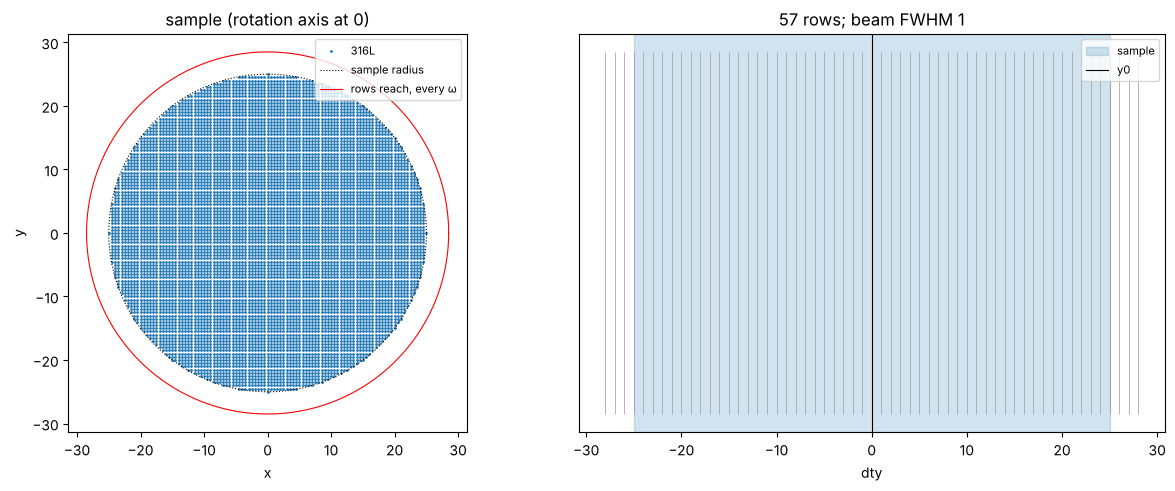

In [4]:
fig = figure("footprint", figsize=(12, 4.8))
pl.plot_footprint(fig, dg.footprint(p))
show(fig)

## 2. Reflections: `--tth-max`

Spots on a ring that runs off the detector are lost wherever they leave it, which an indexer cannot tell from a weak reflection. By default the reflections stop at the largest ring wholly on the detector (top: the fraction of each ring on it, traced from the sample). Lower `tth_max` to render fewer, faster; the rings are re-prepared below if it moves.

tth_max 26.75 deg: reflections 316L: 180; 100% of the outermost ring on the detector


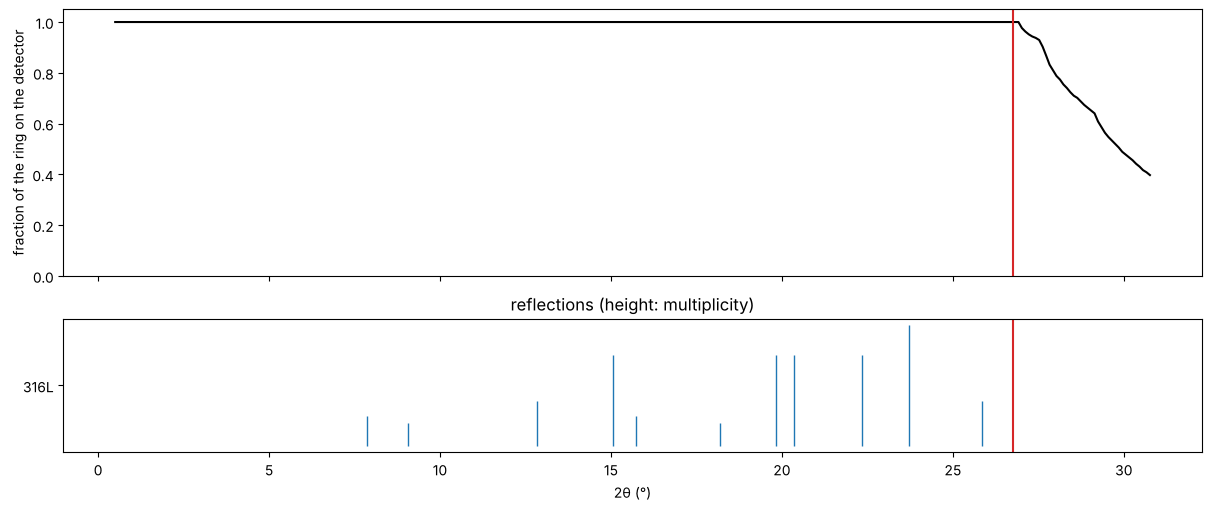

In [5]:
cov = dg.ring_coverage(p)
fig = figure("rings", figsize=(12, 5))
w_tth = interact(fig, pl.plot_rings(fig, cov), tth_max=slider(cov["tth_max"], 2.0, float(cov["tth"][-1]), 0.05,
                                                                "tth_max"))

In [6]:
if not np.isclose(w_tth.kwargs["tth_max"], cov["tth_max"]):
    prepare_file = prepare(tth_max=w_tth.kwargs["tth_max"])
    p = sim.stages.load_prepare(prepare_file)
print(f"tth_max {p['prov']['resolved']['tth_max']:.2f} deg; reflections per phase: "
      + ", ".join(f"{n}: {len(h)}" for n, (_, h, _) in zip(p["names"], p["phases"])))

tth_max 26.75 deg; reflections per phase: 316L: 180


## 3. Counts: `--density`

ImageD11's segmentation keeps only pixels above a cut, so the faint ends and tails of a peak are missing from real data, and the renderer applies the same cut: set `cut` to the threshold your segmentation used on the data you mimic. What then matters is how bright the peaks are against it, which `density` sets (counts per unit density, i.e. per voxel of full density).

A few rows are rendered here without writing them: the middle row and one through the sample's edge. Each peak is judged in the row that sees its voxel best, against the row's summed pixels (overlapping peaks count). Intensities scale with the density, so one render gives every density. **Look for the density where peaks stop disappearing** (left, red): below it, whole weak reflections and the peaks of small or thin features (twins, cells at a grain's edge) are gone from the data, as they would be from a weak measurement; well above it, only the faint ends of each peak are cut (blue: the share of a peak's intensity that survives, and right, at the slider's density).

**Windows** (`--window`, `--max-frames`): each peak is rendered into a window of frames and pixels around it, so the share of a peak left outside its window is lost. Peaks broad in ω (near η = 0 and 180°, or with an orientation spread) get windows of more frames, up to `max_frames`. The plot shows, for each peak centred in the scan, the share of its profile within the scan's ω range that its window misses: what a scan loses at its own ends is not counted against the window. Peaks centred just beyond the ends (the selection reaches as far as the widest window, so a broad one there can still reach the scan) are counted separately; their Friedel mates, 180° away, are in the scan. On the phantom, the dozen peaks that lose ~10% are the broadest, in the widest window: `max_frames = 63` holds them all to within 0.4%, at some cost in time.

[   48.5 s] row 28: 184843 peaks, 35536 of them judged here (39.8 s)


[   65.0 s] row 48: 117805 peaks, 21176 of them judged here (16.4 s)


density 30: 0.0% of the peaks gone; a peak keeps 95% of its intensity (median), 86% (10th percentile)


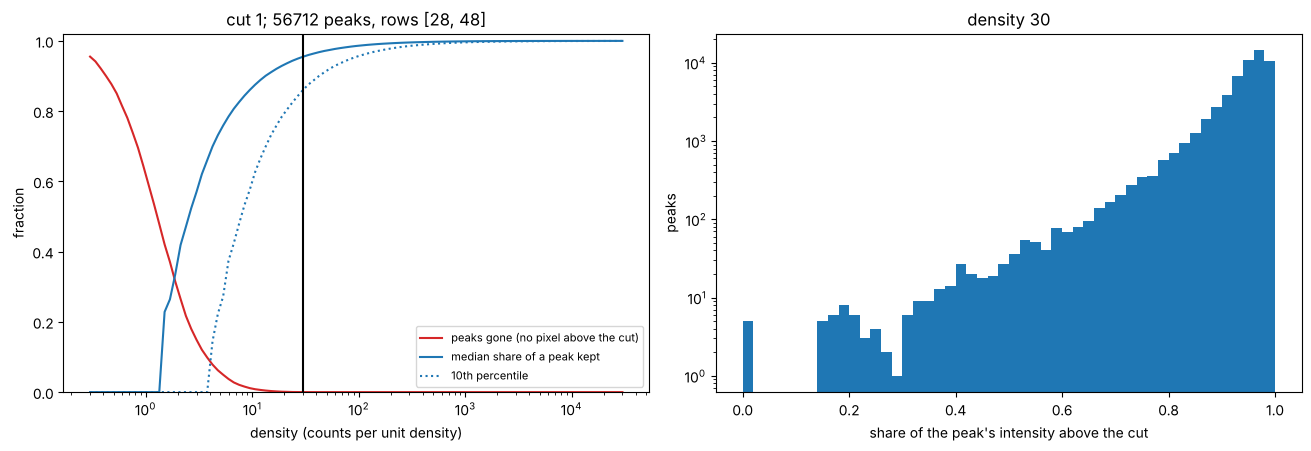

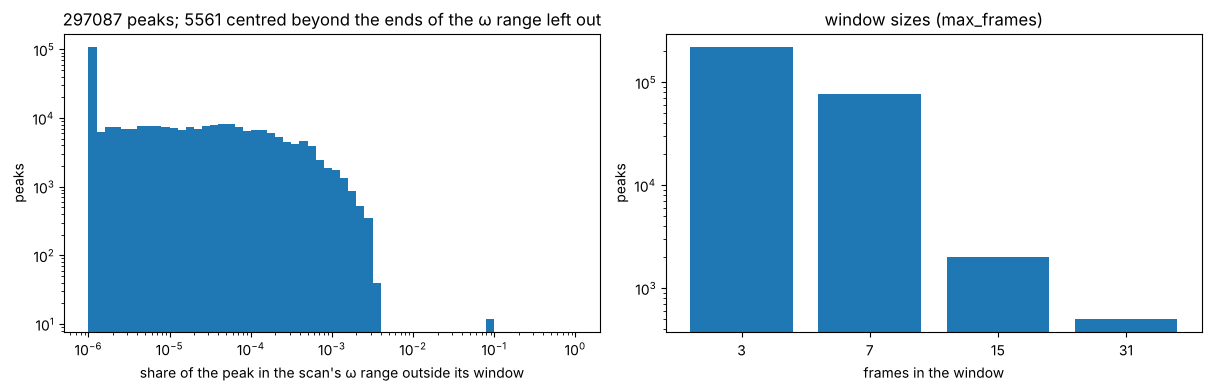

In [7]:
if probe is None:
    mid = p["omega"].shape[0] // 2
    edge = int(np.argmin(np.abs(p["dty"][:, 0] - (p["prov"]["options"]["y0"] + 0.8 * p["prov"]["resolved"]["sample_radius"]))))
    probe = [mid, edge]
probed = dg.probe_rows(p, probe, cut, window, max_frames, log=log)
fig = figure("survival", figsize=(13, 4.4))
w_density = interact(fig, pl.plot_survival(fig, probed), density=widgets.FloatLogSlider(
    value=p["prov"]["options"]["density"], base=10, min=-1, max=4, step=0.05, description="density",
    continuous_update=False))
fig = figure("capture", figsize=(12, 3.8))
pl.plot_capture(fig, probed)
show(fig)

In [8]:
density_used = w_density.kwargs["density"]
if not np.isclose(density_used, p["prov"]["options"]["density"]):
    prepare_file = prepare(density=density_used)
    p = sim.stages.load_prepare(prepare_file)
print(f"density {density_used:g}, cut {cut:g}")

density 30, cut 1


## 4. Render and assemble

Every row of the scan, every phase summed, written above the cut. Rows are independent: on a cluster, split them between jobs with `python -m anri.simulate render <prepare file> --rows a:b` (one file per job), then `assemble` gathers every part made from the prepare file, and refuses if a row is missing or twice. Here it is one job.

In [9]:
render_file = sim.stages.stage_render(prepare_file, cut=cut, window=window, max_frames=max_frames, batch=batch,
                                      command=NOTEBOOK, log=log)
assemble_file = sim.stages.stage_assemble(prepare_file, analysisroot, sample, dataset, peaks_table=peaks_table,
                                          command=NOTEBOOK, log=log)

[   67.8 s] rendering rows 0..56 of 57, 1 phase(s)


[   68.1 s] row 0 (dty -28): 0 peaks (0 outside the omega range), 0 pixels above 1, window capture >= 1.0000 (0.3 s)


[   72.1 s] row 1 (dty -27): 5436 peaks (37 outside the omega range), 0 pixels above 1, window capture >= 0.9979 (4.0 s)


[   77.0 s] row 2 (dty -26): 16831 peaks (148 outside the omega range), 68 pixels above 1, window capture >= 0.9972 (4.9 s)


[   80.9 s] row 3 (dty -25): 31599 peaks (331 outside the omega range), 12377 pixels above 1, window capture >= 0.9970 (3.9 s)


...

[  392.7 s] row 55 (dty 27): 5444 peaks (57 outside the omega range), 0 pixels above 1, window capture >= 0.9303 (1.4 s)


[  393.0 s] row 56 (dty 28): 0 peaks (0 outside the omega range), 0 pixels above 1, window capture >= 1.0000 (0.2 s)


[  393.0 s] -> /tmp/tmpn4z6utjv/am316l_tmap_render.h5 (325 s)


[  393.2 s] 1 part(s), 57 rows, 4407898 pixels -> /tmp/tmpn4z6utjv/am316l/am316l_sim/am316l_sim_sparse.h5, /tmp/tmpn4z6utjv/am316l/am316l_sim/am316l_sim_dataset.h5, /tmp/tmpn4z6utjv/pars/pars.json


[  393.2 s] -> /tmp/tmpn4z6utjv/am316l_tmap_assemble.h5


The middle row of the dataset written, summed over its frames (the Debye-Scherrer rings of spots), and the counts per frame.

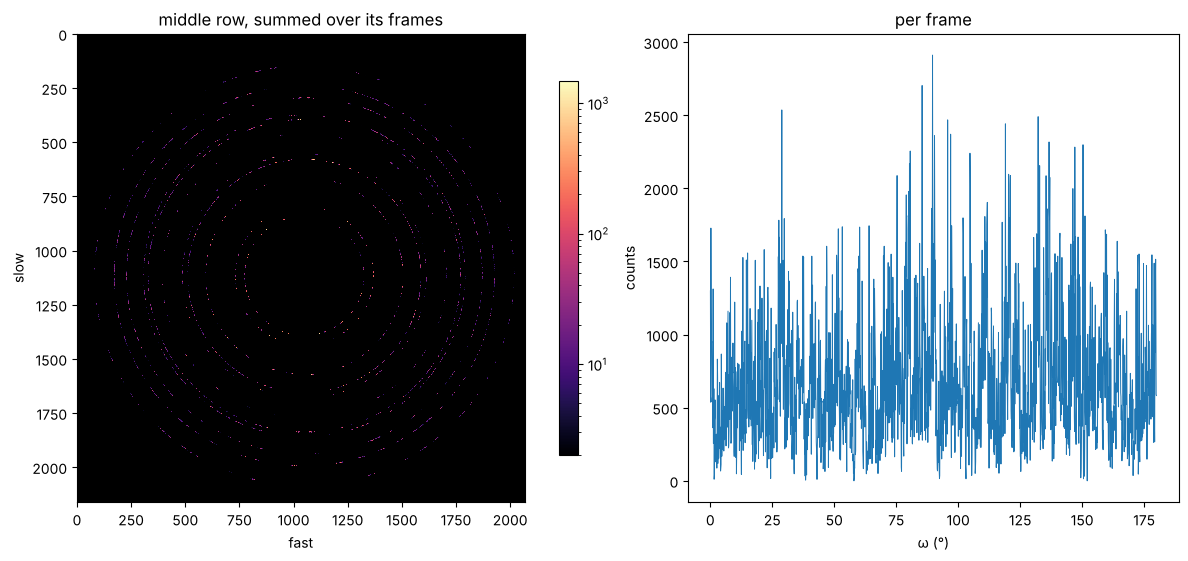

In [10]:
sparse_file = anri.io.provenance.read_provenance(assemble_file)["resolved"]["sparse_file"]
fig = figure("row", figsize=(13, 5.5))
pl.plot_row_image(fig, dg.row_image(sparse_file, p["omega"].shape[0] // 2), "middle row, summed over its frames")
show(fig)

## The command line, and the files

The `python -m anri.simulate run` command that remakes the dataset with every option chosen (`anri.simulate.stages.run_command`), then how the assemble file was made (`anri.io.provenance.show`, as `python -m anri.simulate show`). The dataset can go straight to the [indexing parameters](indexing_parameters.ipynb) notebook (`analysisroot`, `sample`, `dataset`) or to `python -m anri.index`.

In [11]:
print(sim.stages.run_command(assemble_file), end="\n\n")
print(anri.io.provenance.show(assemble_file))

python -m anri.simulate run /home/user/anri/tests/data/phantoms/am316l/am316l_tmap.h5 /tmp/tmpn4z6utjv/geometry.par /tmp/tmpn4z6utjv am316l sim --bandwidth 0.002 --density 30.0 --det-shape 2162 2068 --dty-step 1.0 --margin 3.0 --omega-range 0.0 180.0 --omega-step 0.1 --optics al-crl --pol-factor 1.0 --psf 0.5 --y0 0.0 --batch 65536 --cut 1.0 --max-frames 31 --window 3 7 7

[prepare]
file = '/tmp/tmpn4z6utjv/am316l_tmap_prepare.h5'
anri_version = '0.1.0'
command = 'rendering_parameters.ipynb'
cwd = '/home/user/anri/docs/source/guides'
date = '2026-10-30T11:40:55+00:00'
git_commit = 'ab863e9130d34b84495f90e21ec6b6e85dec9e62'
git_dirty = False
id = '19f40b9500e446238cf7ed011a804685'

[prepare.options]
absorption = True
bandwidth = 0.002
density = 30.0
det_shape = [2162, 2068]
dty_step = 1.0
map = '/home/user/anri/tests/data/phantoms/am316l/am316l_tmap.h5'
margin = 3.0
omega_range = [0.0, 180.0]
omega_step = 0.1
optics = 'al-crl'
pars = '/tmp/tmpn4z6utjv/geometry.par'
pol_factor = 1.0
psf 